In [32]:
import pandas as pd
import matplotlib.pyplot as plt
from datasets import load_dataset
import ast 
import seaborn as sns

dataset = load_dataset('lukebarousse/data_jobs')
df = dataset['train'].to_pandas()

df['job_posted_date'] = pd.to_datetime(df['job_posted_date'])

df['job_skills'] = df['job_skills'].apply(lambda x: ast.literal_eval(x) if pd.notna(x) else x)

df_india_anal = df[(df['job_country'] == 'India') & (df['job_title_short'] == 'Data Analyst')].copy()

In [33]:
df_india_anal = df_india_anal.explode('job_skills')

In [34]:
df_india_anal['job_posted_month'] = df_india_anal['job_posted_date'].dt.month

In [35]:
anal_pivot = df_india_anal.pivot_table(
    index='job_posted_month',
    columns='job_skills',
    aggfunc='size',
    fill_value=0
)

In [36]:
anal_pivot.loc['Total'] = anal_pivot.sum()

In [38]:
anal_pivot = anal_pivot[anal_pivot.loc['Total'].sort_values(ascending=False).index]

In [39]:
anal_pivot = anal_pivot.drop('Total')

In [ ]:
anal_pivot = anal_pivot.reset_index()
anal_pivot['month_posted'] = anal_pivot['job_posted_month'].apply(lambda x : pd.to_datetime(x, format='%m').strftime('%b'))

job_skills,job_posted_month,sql,python,excel,tableau,power bi,r,sas,azure,aws,...,rshiny,suse,ubuntu,twilio,typescript,vue.js,unreal,wrike,workfront,month_posted
0,1,305,216,218,159,98,89,128,46,32,...,0,0,0,1,0,0,0,0,0,Jan
1,2,209,148,156,116,75,67,82,26,33,...,0,0,0,0,0,0,0,0,0,Feb
2,3,229,151,138,125,76,58,62,45,38,...,0,1,0,0,0,0,0,0,0,Mar
3,4,204,143,138,98,83,56,52,40,31,...,0,0,0,0,0,0,0,0,0,Apr
4,5,155,101,106,71,61,42,30,33,22,...,1,0,0,0,0,0,1,0,0,May
5,6,193,150,115,114,77,76,74,37,32,...,0,0,0,0,0,0,0,0,1,Jun
6,7,245,161,174,124,93,67,78,39,31,...,0,0,0,0,0,0,0,0,0,Jul
7,8,317,216,192,152,127,112,98,52,63,...,0,0,1,0,0,0,0,0,0,Aug
8,9,341,229,228,195,168,100,92,35,41,...,0,0,0,0,0,0,0,0,0,Sep
9,10,269,185,193,153,110,95,86,47,48,...,0,0,0,0,0,1,0,0,0,Oct


In [41]:
anal_pivot = anal_pivot.set_index('month_posted')

In [42]:
anal_pivot = anal_pivot.drop(columns='job_posted_month')

In [49]:
monthly_total = df_india_anal.groupby('job_posted_month').size()

In [59]:
anal_pivot_percent = anal_pivot.div(monthly_total.values/100, axis=0)

In [66]:
anal_pivot_percent = anal_pivot_percent.iloc[:, :5]

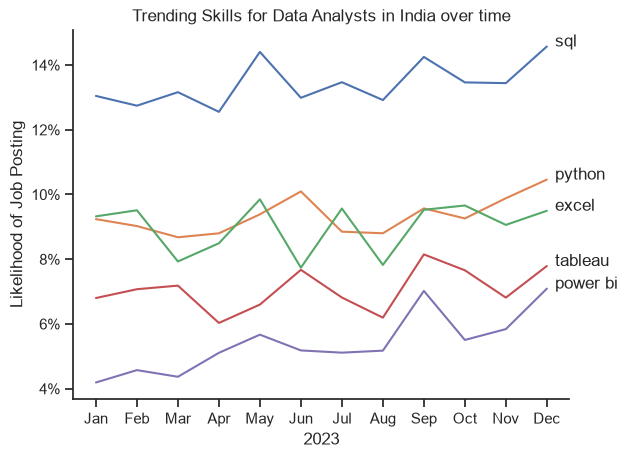

In [89]:
sns.lineplot(data=anal_pivot_percent, dashes=False, legend=False)

sns.set_theme(style='ticks')
sns.despine()
plt.title('Trending Skills for Data Analysts in India over time')
plt.xlabel('2023')
plt.ylabel('Likelihood of Job Posting')

from matplotlib.ticker import PercentFormatter
ax = plt.gca()
ax.yaxis.set_major_formatter(PercentFormatter(decimals=0))

for i in range(5):
    plt.text(11.2, anal_pivot_percent.iloc[-1, i], anal_pivot_percent.columns[i])